In [1]:
import argparse
import json
import logging
import os
import random
import re
import warnings

import torch
from torch import nn
from tqdm import tqdm
from transformers import PreTrainedTokenizer

import linear_rep_geometry as lrg

/home/itai/research/original_lrg/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model_path = "meta-llama/Llama-3.2-3B-Instruct"  # [meta-llama/Llama-3.1-8B-Instruct, meta-llama/Llama-2-7b-hf, meta-llama/Llama-3.2-3B-Instruct]
dataset_type = "valuenet"  # [valuenet]
concept_direction = "pos2neg"  # [pos2neg, pos2neutral]
norm_type = "base"  # [base, norm_sentence_structure, norm_topic]
prompt_type = "reflection"  # [bare, reflection, analysis, implicit, explicit]

# Basic config
model_name = model_path.split('/')[1].lower()
num_sample = 1000
save_dir = "tmp_matrices"
counterfactual_output_path = f"/home/itai/research/linear_rep_geometry/data/ValueNet/schwartz/{concept_direction}/{norm_type}"
analyzed_figure_path = f"/home/itai/research/linear_rep_geometry/figures/{model_name}/{dataset_type}/{concept_direction}/{norm_type}/{prompt_type}"
generation_random_output_path = f"/home/itai/research/linear_rep_geometry/generated/{model_name}/{dataset_type}/{concept_direction}/{norm_type}/{prompt_type}/random.json"
generation_counterfactual_output_path = f"/home/itai/research/linear_rep_geometry/generated/{model_name}/{dataset_type}/{concept_direction}/{norm_type}/{prompt_type}/counterfactual.json"
random_txt_path = f"/home/itai/research/linear_rep_geometry/data/ValueNet/schwartz/random_pairs/{norm_type}/random_1000_pairs.txt"

In [3]:
def get_sequence_pairs(filepath: str, num_samples: int = 1000) -> list[list[str]]:
    with open(filepath, encoding="utf-8") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    if len(lines) > num_samples:
        lines = random.sample(lines, num_samples)
    pairs = [line.split("\t") for line in lines]

    return pairs

In [4]:
def generate_text(
    model: nn.Module,
    tokenizer: PreTrainedTokenizer,
    prompts: list[str],
    prompt_type: str = "bare",
    max_new_tokens: int = 100,
    batch_size: int = 16,
    max_save_step: int = 1000,
) -> list[str]:
    prompt_templates = {
        "reflection": "Consider the deeper meaning behind this: {}\nThis text reflects values related to:",
        "analysis": "Analyzing the underlying principles in: {}\nThe core values expressed here are:",
        "implicit": "Looking at the implicit meaning of: {}\nThe fundamental values shown are:",
        "explicit": "What values are represented in this text: {}\nThe text demonstrates values of:",
        "bare": "{}",
        "theme": "What is the main theme in this text: {}\nKey themes include:",
        "topic": "Identify the primary topics discussed in: {}\nMain topics covered are:",
    }

    if prompt_type not in prompt_templates:
        raise ValueError(
            f"Invalid prompt_type: {prompt_type}. Available types: {list(prompt_templates.keys())}"
        )

    template = prompt_templates[prompt_type]
    formatted_prompts = [template.format(prompt) for prompt in prompts]

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    tokenizer.padding_side = "left"
    generated_texts = []

    # max_save_stepをバッチサイズで考慮
    effective_max_save_step = max_save_step // batch_size * batch_size

    for i in tqdm(
        range(0, len(formatted_prompts), batch_size),
        desc="Generating texts",
        total=len(formatted_prompts) // batch_size
        + bool(len(formatted_prompts) % batch_size),
    ):
        if i > effective_max_save_step:
            break
        batch_prompts = formatted_prompts[i : i + batch_size]
        inputs = tokenizer(
            batch_prompts, return_tensors="pt", padding=True, truncation=True
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                num_return_sequences=1,
                pad_token_id=tokenizer.pad_token_id,
                do_sample=True,
                temperature=0.7,
            )

        decoded_outputs = tokenizer.batch_decode(outputs, skip_special_tokens=True)
        decoded_inputs = tokenizer.batch_decode(
            inputs.input_ids, skip_special_tokens=True
        )

        batch_generated = [
            output[len(input_text) :].strip()
            for output, input_text in zip(decoded_outputs, decoded_inputs, strict=False)
        ]
        generated_texts.extend(batch_generated)

    return generated_texts


def save_generation_results(
    pairs: list[list[str]],
    model: nn.Module,
    tokenizer: PreTrainedTokenizer,
    output_path: str,
    concept_name: str,
    prompt_type: str,
    max_new_tokens: int = 100,
    batch_size: int = 8,
    max_save_step: int = 1000,
) -> None:
    concept_texts = [pair[0] for pair in pairs]
    non_concept_texts = [pair[1] for pair in pairs]

    generated_concept_texts = generate_text(
        model,
        tokenizer,
        concept_texts,
        prompt_type,
        max_new_tokens,
        batch_size,
        max_save_step,
    )
    generated_non_concept_texts = generate_text(
        model,
        tokenizer,
        non_concept_texts,
        prompt_type,
        max_new_tokens,
        batch_size,
        max_save_step,
    )

    results = [
        {
            "concept_text": c_text,
            "non_concept_text": nc_text,
            "generated_text_concept": gc_text,
            "generated_text_non_concept": gnc_text,
        }
        for c_text, nc_text, gc_text, gnc_text in zip(
            concept_texts,
            non_concept_texts,
            generated_concept_texts,
            generated_non_concept_texts,
            strict=False,
        )
    ]

    output_path = output_path.split(".json")[0] + f"_{concept_name}.json"
    print(f"{output_path=}")
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)

## store_matrices

In [8]:
import glob

with torch.inference_mode():
    model = lrg.model
    gamma = (
        model.lm_head.weight.detach()
    )  # Unembedding行列：[語彙サイズ × 隠れ層の次元数]の形状
    W, d = gamma.shape  # W: 語彙サイズ，d: 隠れ層の次元数
    # 行列の中心化(行列の要素を原点に整列)
    gamma_bar = torch.mean(gamma, dim=0)
    centered_gamma = gamma - gamma_bar

# 共分散行列の計算: Unembeddin行列の分布構造のキャプチャ
print("compute Cov(gamma) and transform gamma to g ...")
Cov_gamma = centered_gamma.T @ centered_gamma / W

# 共分散行列の固有分解
eigenvalues, eigenvectors = torch.linalg.eigh(Cov_gamma)

# 逆平方根行列と平方根行列の計算
inv_sqrt_Cov_gamma = (
    eigenvectors @ torch.diag(1 / torch.sqrt(eigenvalues)) @ eigenvectors.T
)
sqrt_Cov_gamma = eigenvectors @ torch.diag(torch.sqrt(eigenvalues)) @ eigenvectors.T

# g: 標準化されたUnembedding行列
g = gamma @ inv_sqrt_Cov_gamma

print(f"{gamma.shape=}")
print(f"{g.shape=}")

# compute concept directions
print("compute concept directions ...")
counterfactual_pair_txt_dir = counterfactual_output_path
filenames = sorted(
    glob.glob(os.path.join(counterfactual_pair_txt_dir, "*.txt"))
)

concept_names = []
for name in filenames:
    base = os.path.basename(name)
    content = os.path.splitext(base)[0][1:-1]
    parts = content.split(" - ")
    if len(parts) == 2:
        concept_names.append(rf"${parts[0]} \Rightarrow {parts[1]}$")
    else:
        concept_names.append(content)

# 概念方向ベクトルの初期化
concept_gamma = torch.zeros(
    len(filenames), W
)  # Unembedding空間での概念方向のベクトルを格納するテンソル
concept_g = torch.zeros(len(filenames), W)  # 標準化空間での概念方向

print(f"[Def]: {concept_gamma.shape=}")
print(f"[Def]: {concept_g.shape=}")

compute Cov(gamma) and transform gamma to g ...
gamma.shape=torch.Size([128256, 3072])
g.shape=torch.Size([128256, 3072])
compute concept directions ...
[Def]: concept_gamma.shape=torch.Size([10, 128256])
[Def]: concept_g.shape=torch.Size([10, 128256])


In [12]:
concept_gamma.shape

torch.Size([10, 128256])

In [ ]:

# counter_factual pairの処理
for i, filename in enumerate(filenames):
    base_sequences, target_sequences, base_encodings, target_encodings = (
        lrg.get_counterfactual_pairs(
            filename, prompt_type=prompt_type, num_sample=int(num_sample)
        )
    )
    # print(f"{len(base_sequences)=}")  # len=[args.num_sample]
    # print(f"{len(target_sequences)=}")  # len=[args.num_sample]
    # print(f"{len(base_encodings)=}")
    # print(f"{len(target_encodings)=}")

    # 概念方向の計算
    mean_diff_gamma, diff_gamma = lrg.concept_direction(
        base_sequences=base_sequences,
        target_sequences=target_sequences,
        base_encodings=base_encodings,
        target_encodings=target_encodings,
        unembedding=gamma
    )
    print(f"{mean_diff_gamma.shape=}")
    print(f"{diff_gamma.shape=}")
    print(f"{concept_gamma.shape=}")

    concept_gamma[i] = torch.mean(mean_diff_gamma, dim=0)

    mean_diff_g, diff_g = lrg.concept_direction(
        base_sequences=base_sequences,
        target_sequences=target_sequences,
        base_encodings=base_encodings,
        target_encodings=target_encodings,
        unembedding=g
    )
    concept_g[i] = torch.mean(mean_diff_g, dim=0)  # 標準化空間での概念方向

# ↑ここまでstore_matrcies.py

---

# ↓ 1_subspace.py

In [6]:
logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)

handler = logging.StreamHandler()
handler.setLevel(logging.INFO)
formatter = logging.Formatter("%(message)s")
handler.setFormatter(formatter)
logger.addHandler(handler)

warnings.filterwarnings("ignore")
device = torch.device("cuda:0")

In [14]:
lrg.load_model(model_path)

Loading checkpoint shards: 100%|██████████| 2/2 [00:01<00:00,  1.33it/s]


In [7]:
matrices_path = "tmp_matrices"
g = torch.load(f"{matrices_path}/g.pt").to(device)
concept_g = torch.load(f"{matrices_path}/concept_g.pt").to(device)
W, d = g.shape

In [9]:
g.shape, concept_g.shape

(torch.Size([128256, 3072]), torch.Size([10, 128256]))

In [10]:
filenames = []
with open(f"{matrices_path}/filenames.txt") as f:
    for line in f.readlines():
        filenames.append(line.strip())

concept_names = []
with open(f"{matrices_path}/concept_names.txt") as f:
    for line in f.readlines():
        concept_names.append(line.strip())

In [11]:
# Get random pairs from file
print("Processing random pairs from file...")
random_pairs = get_sequence_pairs(random_txt_path, int(num_sample))
print(f"{random_pairs=}")

Processing random pairs from file...
random_pairs=[['You know, the left plays a tougher game, it’s very funny. I actually think that the people on the right are tougher', 'laughing at a disabled kids rap during my schools talent show'], ["It's difficult to me make friends or talk with somebody", 'I’m not tall enough to reach the shelf my roommate put the mugs on'], ['being tired of my best friend', 'My friend, Mary, loved the rain.'], ['My cat ate my boogers', "I'm 38 and I've sacrificed all social contact for professional growth."], ['Whenever I’m genuinely happy, not suicidal, and accepting of myself, I get suspicious', 'I think im in love with my best friend but..'], ['I love the taste of expired milk', 'My friend gave me a Gamestop gift card for my birthday and I refuse to use it.'], ['correcting someone about my sexuality', 'I’m not worried about dieing alone,what I’m really worried about is no one experiencing the wonderful side of me I truly love, which One can only understand t

In [9]:
# print("Processing random pairs from file...")
# random_pairs = get_sequence_pairs(random_txt_path, int(num_sample))

# if generation_random_output_path:
#     print("Generating and saving model outputs (Random pairs text) ...")
#     generation_results = save_generation_results(
#         pairs=random_pairs,
#         model=model,
#         tokenizer=tokenizer,
#         concept_name="",
#         prompt_type=prompt_type,
#         output_path=generation_random_output_path,
#         max_new_tokens=int(100),
#         max_save_step=10,
#     )

In [12]:
random_concept_sequences = [pair[0] for pair in random_pairs]
random_non_concept_sequences = [pair[1] for pair in random_pairs]

In [15]:
inner_product_with_counterfactual_pairs_g_LOO = []

num_sample = int(num_sample)
count = 0
for filename in filenames:
    print(f"Processing {filename} ...")
    (
        concept_sequences,
        non_concept_sequences,
        concept_encodings,
        non_concept_encodings,
    ) = lrg.get_counterfactual_pairs(
        filename, prompt_type=prompt_type, num_sample=num_sample
    )
    inner_product_LOO, diff_data = lrg.inner_product_loo(
        base_sequences=concept_sequences,
        target_sequences=non_concept_sequences,
        base_encodings=concept_encodings,
        target_encodings=non_concept_encodings,
        unembedding=g,
    )
    inner_product_with_counterfactual_pairs_g_LOO.append(inner_product_LOO)
    count += 1

    ## Generate next tokens
    counterfactual_pairs = get_sequence_pairs(
        filename, num_samples=int(num_sample)
    )
    pattern = r"\[(.*?)\("
    match1 = re.search(pattern, filename.split("/")[-1])
    concept_name = match1.group(1)
    # if generation_random_output_path:
    #     print("Generating and saving model outputs (Counterfactual pairs text) ...")
    #     generation_results = save_generation_results(
    #         pairs=counterfactual_pairs,
    #         model=model,
    #         tokenizer=tokenizer,
    #         prompt_type=prompt_type,
    #         output_path=generation_counterfactual_output_path,
    #         max_new_tokens=int(100),
    #         concept_name=concept_name,
    #         max_save_step=10,
    #     )

Processing /home/itai/research/linear_rep_geometry/data/ValueNet/schwartz/pos2neg/base/[Achievement(Positive) - Achievement(Negative)].txt ...
Computing base hidden states...


Processing embeddings: 100%|██████████| 250/250 [00:31<00:00,  7.95batch/s]


Computing target hidden states...


Processing embeddings: 100%|██████████| 250/250 [00:31<00:00,  8.04batch/s]


diff_unembedding.shape=torch.Size([1000, 128256])
Processing /home/itai/research/linear_rep_geometry/data/ValueNet/schwartz/pos2neg/base/[Benevolence(Positive) - Benevolence(Negative)].txt ...
Computing base hidden states...


...

diff_unembedding.shape=torch.Size([1000, 128256])
Processing /home/itai/research/linear_rep_geometry/data/ValueNet/schwartz/pos2neg/base/[Universalism(Positive) - Universalism(Negative)].txt ...
Computing base hidden states...


Processing embeddings: 100%|██████████| 250/250 [00:29<00:00,  8.36batch/s]


Computing target hidden states...


Processing embeddings: 100%|██████████| 250/250 [00:32<00:00,  7.78batch/s]


diff_unembedding.shape=torch.Size([1000, 128256])


In [16]:
print("Computing embeddings for random pairs...")
(
    random_base_sequences,
    random_target_sequences,
    random_base_encodings,
    random_target_encodings,
) = lrg.get_counterfactual_pairs(
    random_txt_path, prompt_type=prompt_type, num_sample=num_sample
)
print(f"{len(random_base_encodings)=}, {len(random_target_encodings)=}")

Computing embeddings for random pairs...
len(random_base_encodings)=1000, len(random_target_encodings)=1000


In [17]:
# len(random_base_encodings)=1000, len(random_target_encodings)=1000
random_mean_diff_unembedding, random_diff_unembedding = lrg.concept_direction(
    base_sequences=random_base_sequences,
    target_sequences=random_target_sequences,
    base_encodings=random_base_encodings,
    target_encodings=random_target_encodings,
    unembedding=g,
)

Computing base hidden states...


Processing embeddings: 100%|██████████| 250/250 [00:26<00:00,  9.59batch/s]


Computing target hidden states...


Processing embeddings: 100%|██████████| 250/250 [00:26<00:00,  9.27batch/s]

Computing unembeddings...


In [18]:
# print(f"{len(inner_product_with_counterfactual_pairs_g_LOO)=}") # 10
print(f"{random_mean_diff_unembedding.shape=}") # torch.Size([3072])
print(f"{random_diff_unembedding.shape=}") # torch.Size([3072])
print(f"{concept_g.shape=}") # torch.Size([10, 3072])

random_mean_diff_unembedding.shape=torch.Size([1000, 128256])
random_diff_unembedding.shape=torch.Size([1000, 128256])
concept_g.shape=torch.Size([10, 128256])


In [19]:
random_diff_unembedding.shape

torch.Size([1000, 128256])

In [20]:
print(f"{len(inner_product_with_counterfactual_pairs_g_LOO)=}")
print(f"{inner_product_with_counterfactual_pairs_g_LOO[0].shape}")
print(f"{random_diff_unembedding.shape=}")
print(f"{concept_g.shape=}")

len(inner_product_with_counterfactual_pairs_g_LOO)=10
torch.Size([1000])
random_diff_unembedding.shape=torch.Size([1000, 128256])
concept_g.shape=torch.Size([10, 128256])


In [40]:
random_diff_unembedding

tensor([[  42.4847,   27.2350,  -24.7168,  ...,   52.9281,   52.9422,
           52.9509],
        [ -67.5949,   26.6754,    5.6849,  ...,   16.7556,   16.7406,
           16.7553],
        [  19.9455,   56.0271,   30.8629,  ...,   11.4158,   11.4305,
           11.4212],
        ...,
        [ -45.1548,  -40.7837,  -25.7669,  ...,  -18.5330,  -18.5350,
          -18.5422],
        [ -33.2115,   -4.8519,  -43.3991,  ..., -111.1748, -111.1644,
         -111.1818],
        [  44.0564,   49.5965,    3.4055,  ...,  -18.2943,  -18.2998,
          -18.2816]], device='cuda:0')

In [41]:
concept_g

tensor([[-8.0240e-06, -2.1731e-05,  3.4374e-06,  ...,  5.0628e-06,
          5.0665e-06,  5.0692e-06],
        [-8.5856e-06, -1.2584e-05,  2.4183e-06,  ...,  9.8488e-06,
          9.8487e-06,  9.8484e-06],
        [-3.1524e-05, -1.2625e-05, -7.2956e-06,  ...,  1.3412e-05,
          1.3415e-05,  1.3418e-05],
        ...,
        [ 1.3237e-05, -2.2367e-05,  1.1020e-05,  ..., -4.0572e-07,
         -3.9892e-07, -4.0128e-07],
        [-4.6851e-06, -1.0032e-05,  4.3085e-06,  ...,  1.0486e-05,
          1.0488e-05,  1.0490e-05],
        [-1.1420e-05,  4.1689e-06,  8.7194e-07,  ...,  4.5247e-06,
          4.5255e-06,  4.5260e-06]], device='cuda:0')

In [38]:
inner_product_with_counterfactual_pairs_g_LOO

[tensor([ 1.4698e+04,  9.9160e+00, -1.4041e+04,  1.0176e+04,  6.1683e+03,
          5.5130e+03,  3.0883e+03,  4.9264e+03, -7.9220e+03,  5.8930e+03,
          4.2003e+03,  6.5462e+03, -1.0010e+04,  1.7437e+04,  1.5343e+03,
          7.5761e+03, -8.5803e+03, -1.1153e+02,  5.7547e+03,  6.5471e+02,
          3.7542e+03,  9.8335e+03,  6.6037e+03,  2.2585e+03, -6.4509e+03,
          7.6302e+03, -1.4071e+04, -3.2321e+03,  2.9010e+03,  4.4230e+03,
          1.4084e+04,  5.6221e+03,  1.1458e+04,  7.5049e+03,  1.4880e+03,
          1.1085e+04, -1.1870e+04, -1.1988e+04,  1.8936e+04,  3.4255e+03,
         -5.3332e+03,  6.1679e+03, -4.6108e+03,  4.6677e+03,  1.8005e+04,
          1.0134e+03, -1.1786e+03,  1.2727e+04,  7.9190e+03,  8.0989e+03,
          3.5613e+03,  2.4220e+03,  1.0101e+03, -1.1519e+04,  1.9950e+04,
          4.3869e+03,  8.4025e+03,  1.2120e+04,  8.5275e+03,  1.3438e+04,
         -1.0260e+04, -3.4002e+03,  6.0731e+03,  1.8161e+04, -7.3568e+03,
          1.5483e+04,  4.9610e+03, -2.

Saved histogram figure at: /home/itai/research/linear_rep_geometry/figures/llama-3.2-3b-instruct/valuenet/pos2neg/base/reflection/concept_direction_LOO_g.png


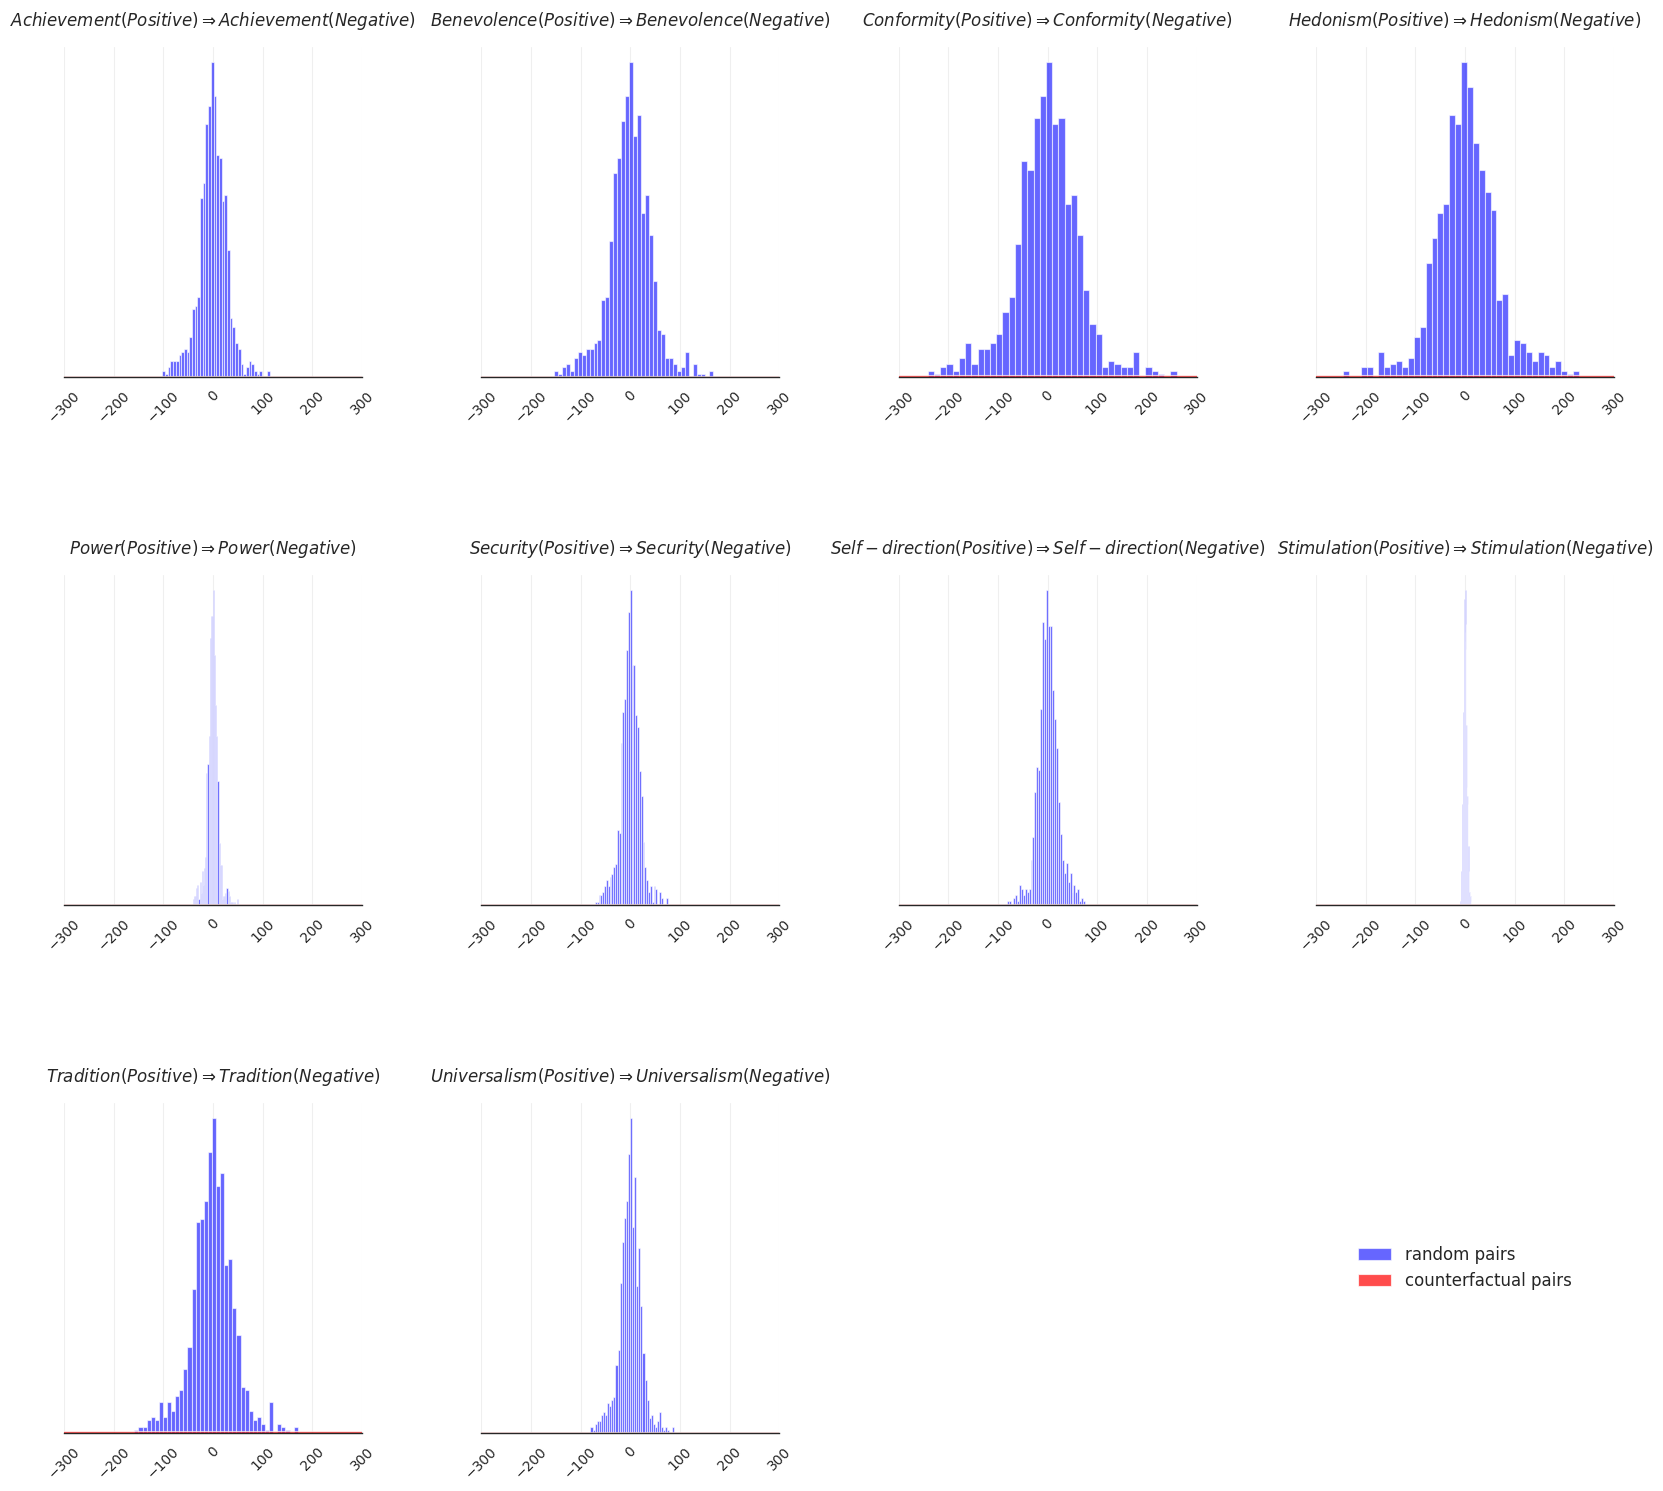

In [32]:
from matplotlib import pyplot as plt
import os

def show_histogram_LOO(
    inner_product_with_counterfactual_pairs_LOO,
    random_pairs,
    concept,
    concept_names,
    save_dir,
    fig_name="gamma",
    cols=4,
    title_fontsize=12,
    x_lim=(-5000, 5000),  # x軸の範囲を制限
):
    n_plots = concept.shape[0]
    cols = min(cols, n_plots)
    rows = (n_plots + cols - 1) // cols

    fig_height = 6 * rows
    fig_width = 5 * cols
    fig = plt.figure(figsize=(fig_width, fig_height))

    gs = fig.add_gridspec(rows, cols, hspace=0.6, wspace=0.4)
    axs = []
    for i in range(rows):
        for j in range(cols):
            axs.append(fig.add_subplot(gs[i, j]))

    for i in range(len(axs)):
        if i < n_plots:
            target = inner_product_with_counterfactual_pairs_LOO[i]
            baseline = random_pairs @ concept[i]

            axs[i].hist(
                baseline.cpu().numpy(),
                bins=40,
                alpha=0.6,
                color="blue",
                label="random pairs",
                density=True,
            )
            axs[i].hist(
                target.cpu().numpy(),
                bins=40,
                alpha=0.7,
                color="red",
                label="counterfactual pairs",
                density=True,
            )
            axs[i].set_xlim(x_lim)  # x軸の範囲を制限
            axs[i].set_yticks([])

            title = concept_names[i] if i < len(concept_names) else f"Concept {i}"
            axs[i].set_title(title, fontsize=title_fontsize, pad=15)

            axs[i].tick_params(axis="x", labelrotation=45, labelsize=10)
            axs[i].grid(True, alpha=0.3)

            axs[i].spines["top"].set_visible(False)
            axs[i].spines["right"].set_visible(False)
            axs[i].spines["left"].set_visible(False)
        else:
            axs[i].axis("off")

    handles, labels = axs[0].get_legend_handles_labels()
    legend_ax = axs[-1] if n_plots < len(axs) else axs[-1]
    legend_ax.legend(handles, labels, loc="center", fontsize=12, frameon=False)
    legend_ax.axis("off")

    os.makedirs(save_dir, exist_ok=True)

    save_path = os.path.join(save_dir, f"concept_direction_LOO_{fig_name}.png")
    plt.savefig(save_path, bbox_inches="tight", dpi=300)
    print(f"Saved histogram figure at: {save_path}")
    plt.show()

# 使用例
show_histogram_LOO(
    inner_product_with_counterfactual_pairs_g_LOO,
    random_diff_unembedding,
    concept_g,
    concept_names,
    fig_name="g",
    save_dir=analyzed_figure_path,
    x_lim=(-300, 300),  # 必要に応じて範囲を調整
)
